# Reconnaissance de billets de banque par ORB + RANSAC
**Cours de Reconnaissance des formes – Master 1 IA & Sciences des données (UNIKIN)**
**Sujet 39, variante A** : reconnaissance de billets de banque (francs congolais) par descripteurs ORB,
appariement de Hamming et estimation robuste d'une homographie par RANSAC, par rapport à des images de référence.

Ce notebook sert à la démonstration de la soutenance. Il suit la chaîne de traitement pas à pas, puis
reprend les résultats chiffrés du protocole complet (`code/experiences.py`) et compare avec la variante B
(histogrammes de couleur HSV + texture LBP + k-NN). Aucune méthode d'apprentissage profond n'est utilisée.

**Sur Google Colab** : cloner le dépôt (`!git clone <url> reconnaissance_formes` dans `/content`) ou téléverser
l'archive du projet, puis exécuter les cellules dans l'ordre. Les images des billets congolais (site de la Banque Centrale
du Congo) sont fournies dans `donnees/billets_cdf/` ; celles des billets étrangers, qui servent de billets inconnus,
sont téléchargées automatiquement.

In [1]:
import os, sys, glob, json, zipfile
from pathlib import Path

# Sur Colab : décompresser l'archive du projet si elle a été téléversée
if Path('/content').exists() and not Path('/content/reconnaissance_formes').exists():
    archives = glob.glob('/content/*.zip')
    if archives:
        zipfile.ZipFile(archives[0]).extractall('/content')
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'opencv-python-headless', 'scikit-image'])
if Path('/content/reconnaissance_formes').exists():
    RACINE = Path('/content/reconnaissance_formes')
else:  # exécution locale : le notebook est à la racine du projet
    RACINE = Path('.').resolve() if (Path('.') / 'code').exists() else Path('..').resolve()
sys.path.insert(0, str(RACINE / 'code'))
os.chdir(RACINE / 'code')

# Images de billets absentes (dépôt public) : téléchargement depuis la source d'origine
if not any((RACINE / 'donnees' / 'billets_publics').glob('*.jpg')):
    import subprocess
    subprocess.run([sys.executable, 'telecharger_billets.py', '--sortie', str(RACINE / 'donnees' / 'billets_publics')], check=True)

import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd
from billets import ReconnaisseurORB, ReconnaisseurHistogrammes, charger_image, INCONNU
from billets.pretraitement import preparer_gris, redimensionner
from billets.synthese import generer_photo, CATEGORIES
from billets.evaluation import iou_quadrilateres
from config_billets import CONNUS, FACES, chemin_reference, chemin_source, charger_references
from demo import annoter, dessiner_appariements
print('OpenCV', cv2.__version__, '| racine du projet :', RACINE)
DONNEES = RACINE / 'donnees'
source = lambda nom: charger_image(chemin_source(DONNEES, nom))
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

OpenCV 5.0.0 | racine du projet : /opt/reconnaissance_formes


## 1. Les images de référence
Le système doit reconnaître les cinq coupures demandées par le sujet : 500, 1 000, 5 000, 10 000 et 20 000 FC.
Il ne dispose que d'**une seule image de référence par face**, soit 10 références, tirées des images officielles
de la Banque Centrale du Congo (www.bcc.cd). Les faces que la BCC ne publie qu'avec des pastilles numérotées
ont été nettoyées automatiquement (`code/preparer_billets_cdf.py`).

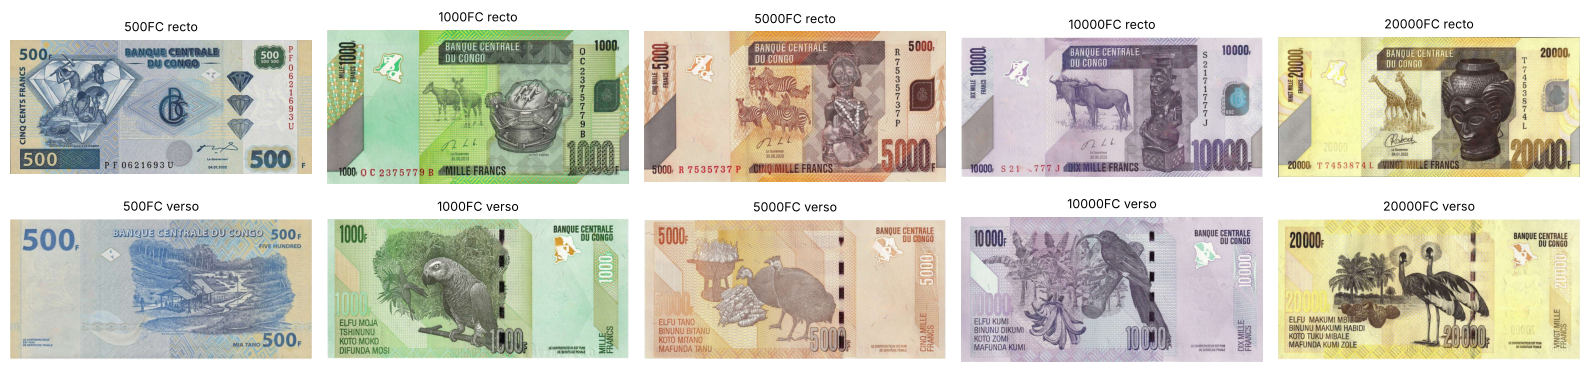

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(16, 4))
for j, c in enumerate(CONNUS):
    for i, face in enumerate(FACES):
        axes[i, j].imshow(rgb(charger_image(chemin_reference(DONNEES, c, face))))
        axes[i, j].set_title(f'{c} {face}', fontsize=9); axes[i, j].axis('off')
plt.tight_layout(); plt.show()

## 2. Étape 1 – Points d'intérêt ORB
ORB = détecteur **FAST** orienté (orientation par centroïde d'intensité) + descripteur **BRIEF** binaire de
256 bits « tourné » selon cette orientation, calculé sur une pyramide de 8 échelles (facteur 1,2).
Prétraitement : niveaux de gris + égalisation locale CLAHE.

500FC    recto   2000 points ORB
500FC    verso   2000 points ORB
1000FC   recto   2000 points ORB
1000FC   verso   2000 points ORB
5000FC   recto   2000 points ORB
5000FC   verso   2000 points ORB
10000FC  recto   2000 points ORB
10000FC  verso   2000 points ORB
20000FC  recto   2000 points ORB
20000FC  verso   2000 points ORB


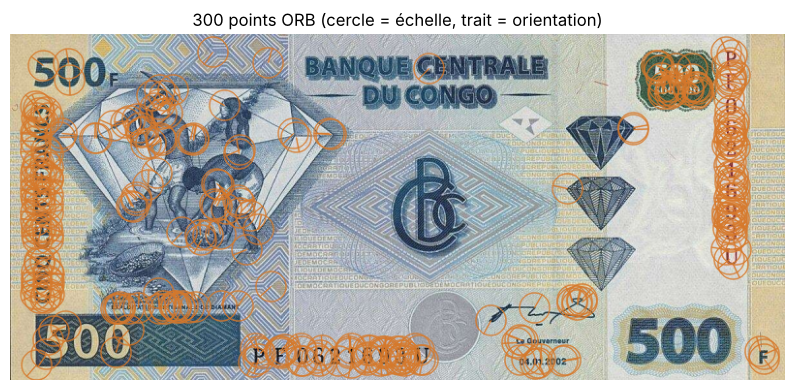

Un descripteur ORB = 32 octets = 256 bits


In [3]:
syn = json.load(open(RACINE / 'resultats' / 'synthese.json', encoding='utf-8'))
reco = charger_references(ReconnaisseurORB(**syn['A']['parametres']), DONNEES, charger_image)  # configuration retenue
for r in reco.references:
    print(f"{r['classe']:8s} {r['face']:6s} {len(r['kp']):5d} points ORB")
ref = reco.references[0]
vis = cv2.drawKeypoints(ref['image'], ref['kp'][:300], None, color=(42,120,214),
                        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10,5)); plt.imshow(rgb(vis)); plt.axis('off'); plt.title('300 points ORB (cercle = échelle, trait = orientation)'); plt.show()
print('Un descripteur ORB =', ref['des'].shape[1], 'octets =', ref['des'].shape[1]*8, 'bits')

## 3. Étapes 2 à 4 – Appariement de Hamming, test de ratio de Lowe, RANSAC
On fabrique une photo difficile (perspective forte, fond encombré) dont on connaît la vérité terrain,
puis on suit chaque étape.

In [4]:
rng = np.random.default_rng(7)
photo, quad_vrai = generer_photo(rng, source('5000FC_recto'), 'perspective', distracteur=source('200FC_recto'))

kp, des, f, forme = reco.extraire(photo)
ref = next(r for r in reco.references if r['classe'] == '5000FC' and r['face'] == 'recto')
paires = reco.apparieur.knnMatch(ref['des'], des, k=2)
bons = [m for m, *n in paires if n and m.distance < 0.75 * n[0].distance]
src = np.float32([ref['kp'][m.queryIdx].pt for m in bons]).reshape(-1,1,2)
dst = np.float32([kp[m.trainIdx].pt for m in bons]).reshape(-1,1,2)
H, masque = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
print(f'points ORB dans la photo        : {len(kp)}')
print(f'appariements bruts (k=2)         : {len(paires)}')
print(f'après test de ratio de Lowe 0.75 : {len(bons)}')
print(f'inliers RANSAC (homographie)     : {int(masque.sum())}')
print('Homographie estimée H =\n', np.round(H, 3))

points ORB dans la photo        : 2000
appariements bruts (k=2)         : 2000
après test de ratio de Lowe 0.75 : 70
inliers RANSAC (homographie)     : 62
Homographie estimée H =
 [[-4.19000e-01 -1.89000e-01  7.25419e+02]
 [-8.50000e-02 -7.00000e-01  6.51754e+02]
 [ 0.00000e+00 -0.00000e+00  1.00000e+00]]


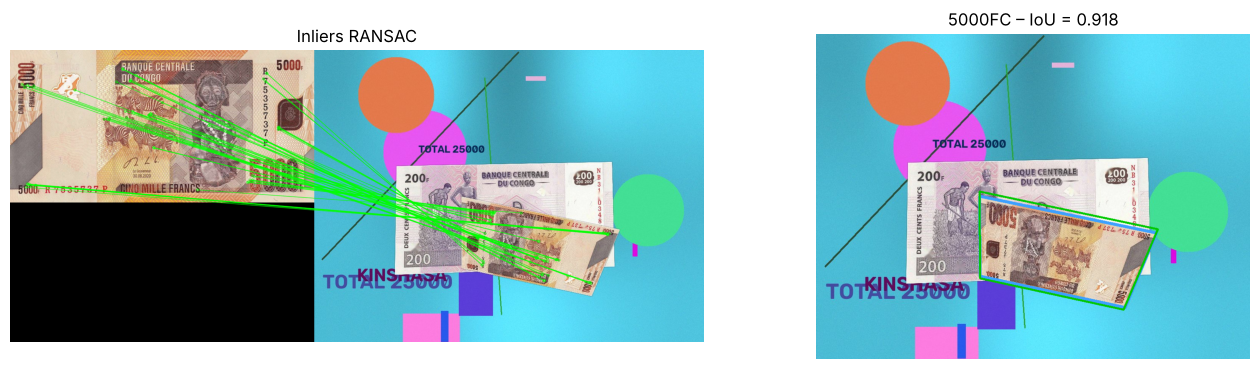

Scores (inliers) par billet de référence : {'5000FC': 62, '500FC': 22, '1000FC': 7, '10000FC': 0, '20000FC': 0}


In [5]:
res = reco.predire(photo, details=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios':[1.6,1]})
axes[0].imshow(rgb(dessiner_appariements(photo, res, 60))); axes[0].axis('off'); axes[0].set_title('Inliers RANSAC')
vis = photo.copy()
cv2.polylines(vis, [quad_vrai.astype(np.int32)], True, (255,160,60), 6)
cv2.polylines(vis, [res['polygone'].astype(np.int32)], True, (0,200,0), 3)
axes[1].imshow(rgb(vis)); axes[1].axis('off')
axes[1].set_title(f"{res['classe']} – IoU = {iou_quadrilateres(res['polygone'], quad_vrai):.3f}")
plt.show()
print('Scores (inliers) par billet de référence :', dict(sorted(res['scores'].items(), key=lambda x: -x[1])))

## 4. Étape 5 – Décision en monde ouvert (rejet des billets inconnus)
La coupure retenue est celle qui a le plus d'inliers ; si ce nombre est inférieur au seuil **τ**
(choisi sur le jeu de validation), la photo est rejetée. Exemples : deux coupures congolaises qui ne font pas
partie des billets à reconnaître (100 et 200 FC, de même maquette que les coupures connues), un billet étranger
et une scène sans billet.

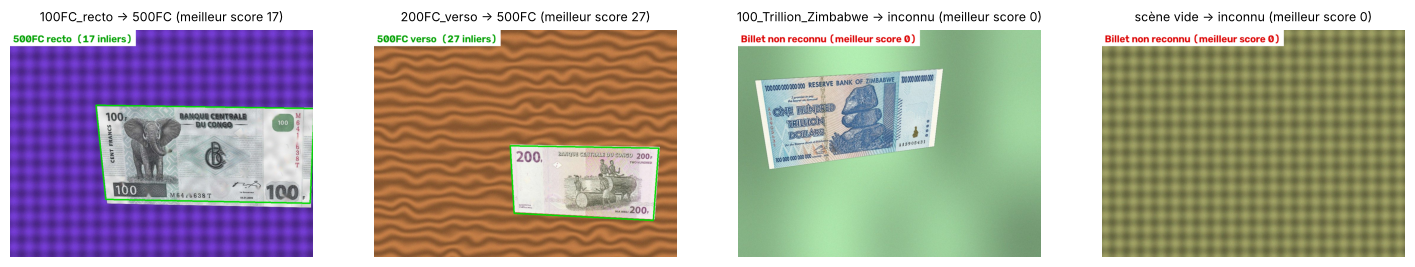

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
cas = [('100FC_recto', 'facile'), ('200FC_verso', 'rotation'), ('100_Trillion_Zimbabwe', 'facile'), (None, 'facile')]
for ax, (nom, cat) in zip(axes, cas):
    img, _ = generer_photo(rng, source(nom) if nom else None, cat)
    r = reco.predire(img)
    ax.imshow(rgb(annoter(img, r))); ax.axis('off')
    ax.set_title(f"{nom or 'scène vide'} -> {r['classe']} (meilleur score {r['score']})", fontsize=9)
plt.show()

## 5. Démonstration sur toutes les difficultés
Une photo par catégorie : rotation, perspective, petite échelle, éclairage, flou, occlusion par la main,
billet froissé, forte compression.

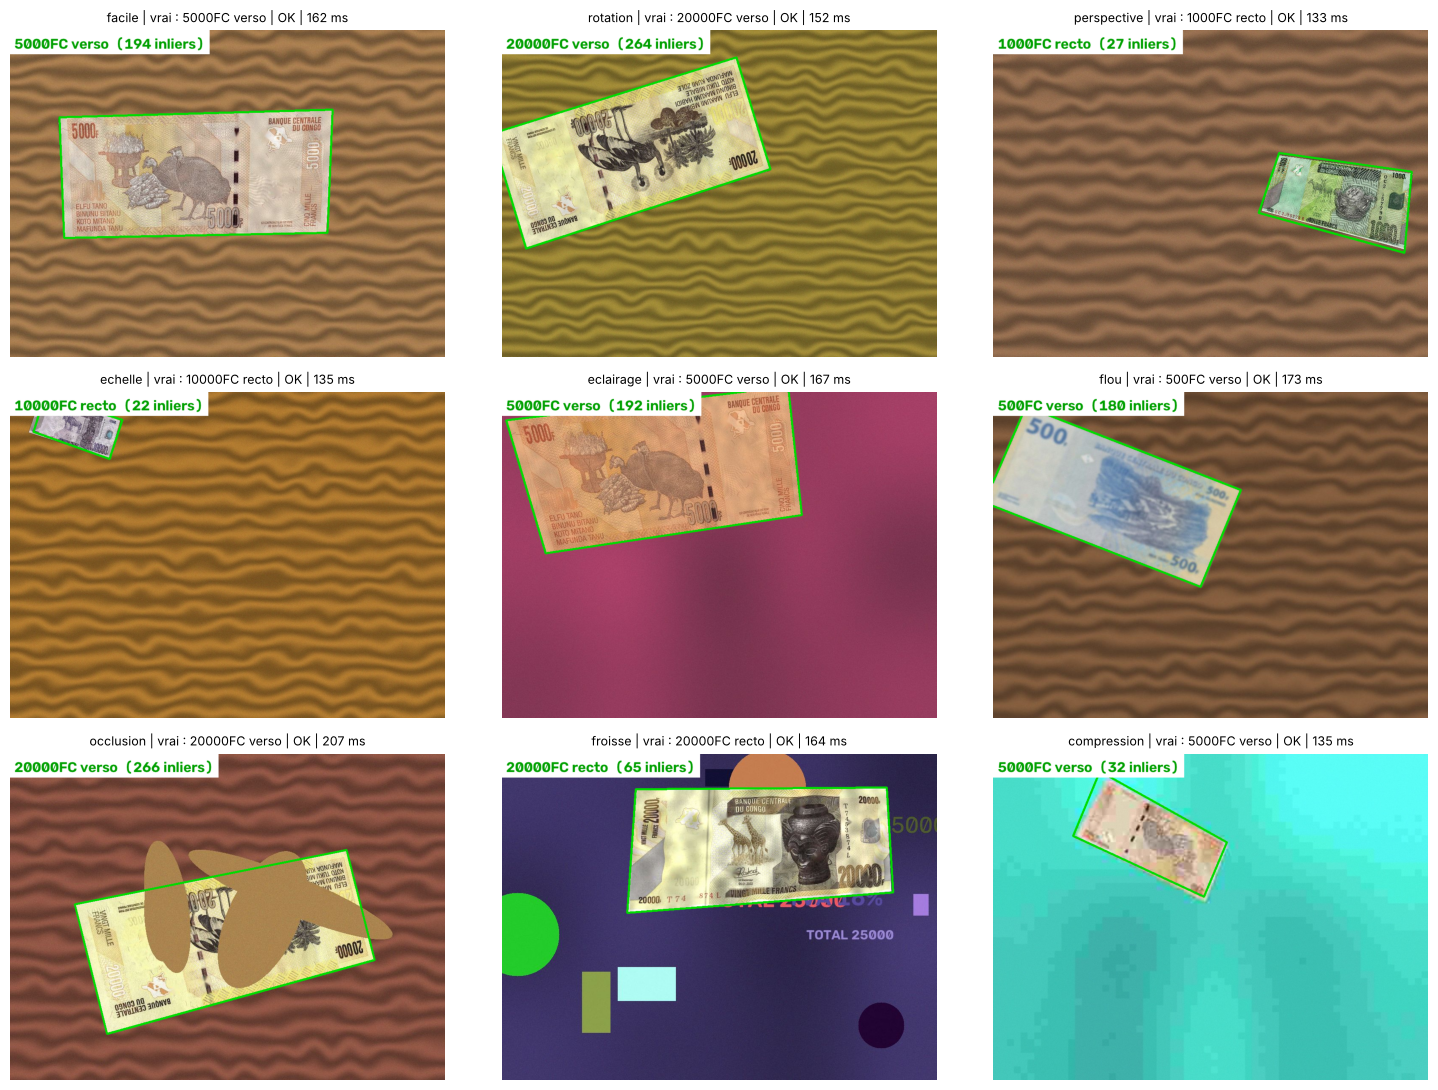

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, cat in zip(axes.ravel(), CATEGORIES):
    c, face = CONNUS[rng.integers(len(CONNUS))], FACES[rng.integers(2)]
    img, quad = generer_photo(rng, source(f'{c}_{face}'), cat)
    r = reco.predire(img)
    ok = 'OK' if r['classe'] == c else 'ERREUR'
    ax.imshow(rgb(annoter(img, r))); ax.axis('off')
    ax.set_title(f"{cat} | vrai : {c} {face} | {ok} | {r['temps_ms']:.0f} ms", fontsize=9)
plt.tight_layout(); plt.show()

**Lecture des erreurs.** Les échecs, quand il y en a sur ce tirage, sont de deux types typiques. Un billet minuscule
(petite échelle) ou froissé ne donne pas assez d'inliers cohérents avec une seule homographie : il est rejeté
comme « inconnu ». Un billet en partie hors de l'image ou caché par la main perd une partie de ses points, ce qui
peut le faire passer sous le seuil. Ce sont les deux catégories les plus faibles du test (76 % et 84 %),
discutées dans le rapport.

## 6. Résultats du protocole complet
`code/construire_jeux.py` génère 444 photos de validation, 914 photos de test et 1 002 photos d'apprentissage
pour la variante B ; `code/experiences.py` règle les hyperparamètres sur la validation puis mesure une seule
fois sur le test. Le test contient 450 photos des cinq coupures connues et 464 photos sans billet connu, jamais vues
pendant les réglages : les coupures de 100 et 200 FC (même maquette que les billets connus), 34 billets étrangers
et 50 scènes sans billet. On recharge ici ses résultats.

In [8]:
RES = RACINE / 'resultats'
cles = ['exactitude','precision_macro','rappel_macro','f1_macro','taux_identification','taux_confusion',
        'taux_faux_rejet','taux_fausse_acceptation','temps_ms_moyen']
tab = pd.DataFrame({'A : ORB + RANSAC': {k: syn['A']['test'][k] for k in cles},
                    'B : HSV + LBP + k-NN': {k: syn['B']['test'][k] for k in cles}}).round(3)
print('Configuration A :', syn['A']['configuration'], '| tau =', syn['A']['tau'])
print('Configuration B :', syn['B']['descripteurs'], '| k =', syn['B']['k'], '| delta =', round(syn['B']['delta'], 3))
print('Localisation A : IoU moyen =', round(syn['A']['test']['iou_moyen'], 3),
      '| part IoU > 0,5 =', round(syn['A']['test']['part_iou_sup_0_5'], 3))
tab

Configuration A : pyramide 12 niveaux + vérification photométrique | tau = 8
Configuration B : couleur seule | k = 1 | delta = 0.626
Localisation A : IoU moyen = 0.955 | part IoU > 0,5 = 0.998


,A : ORB + RANSAC,B : HSV + LBP + k-NN
exactitude,0.928,0.416
precision_macro,0.939,0.292
rappel_macro,0.936,0.244
f1_macro,0.932,0.263
taux_identification,0.936,0.244
taux_confusion,0.002,0.193
taux_faux_rejet,0.062,0.562
taux_fausse_acceptation,0.080,0.418
temps_ms_moyen,446.187,52.993


In [9]:
pd.read_csv(RES / 'test_par_categorie.csv').round(3)

,categorie,A_identification,B_identification,A_fausse_acceptation,B_fausse_acceptation
0,facile,1.00,0.40,0.169,0.373
1,rotation,1.00,0.26,0.196,0.391
2,perspective,0.96,0.20,0.130,0.478
3,echelle,0.76,0.14,0.000,0.522
4,eclairage,1.00,0.12,0.103,0.241
5,flou,0.94,0.38,0.017,0.424
6,occlusion,0.92,0.18,0.043,0.565
7,froisse,0.84,0.28,0.000,0.500
8,compression,1.00,0.24,0.052,0.345


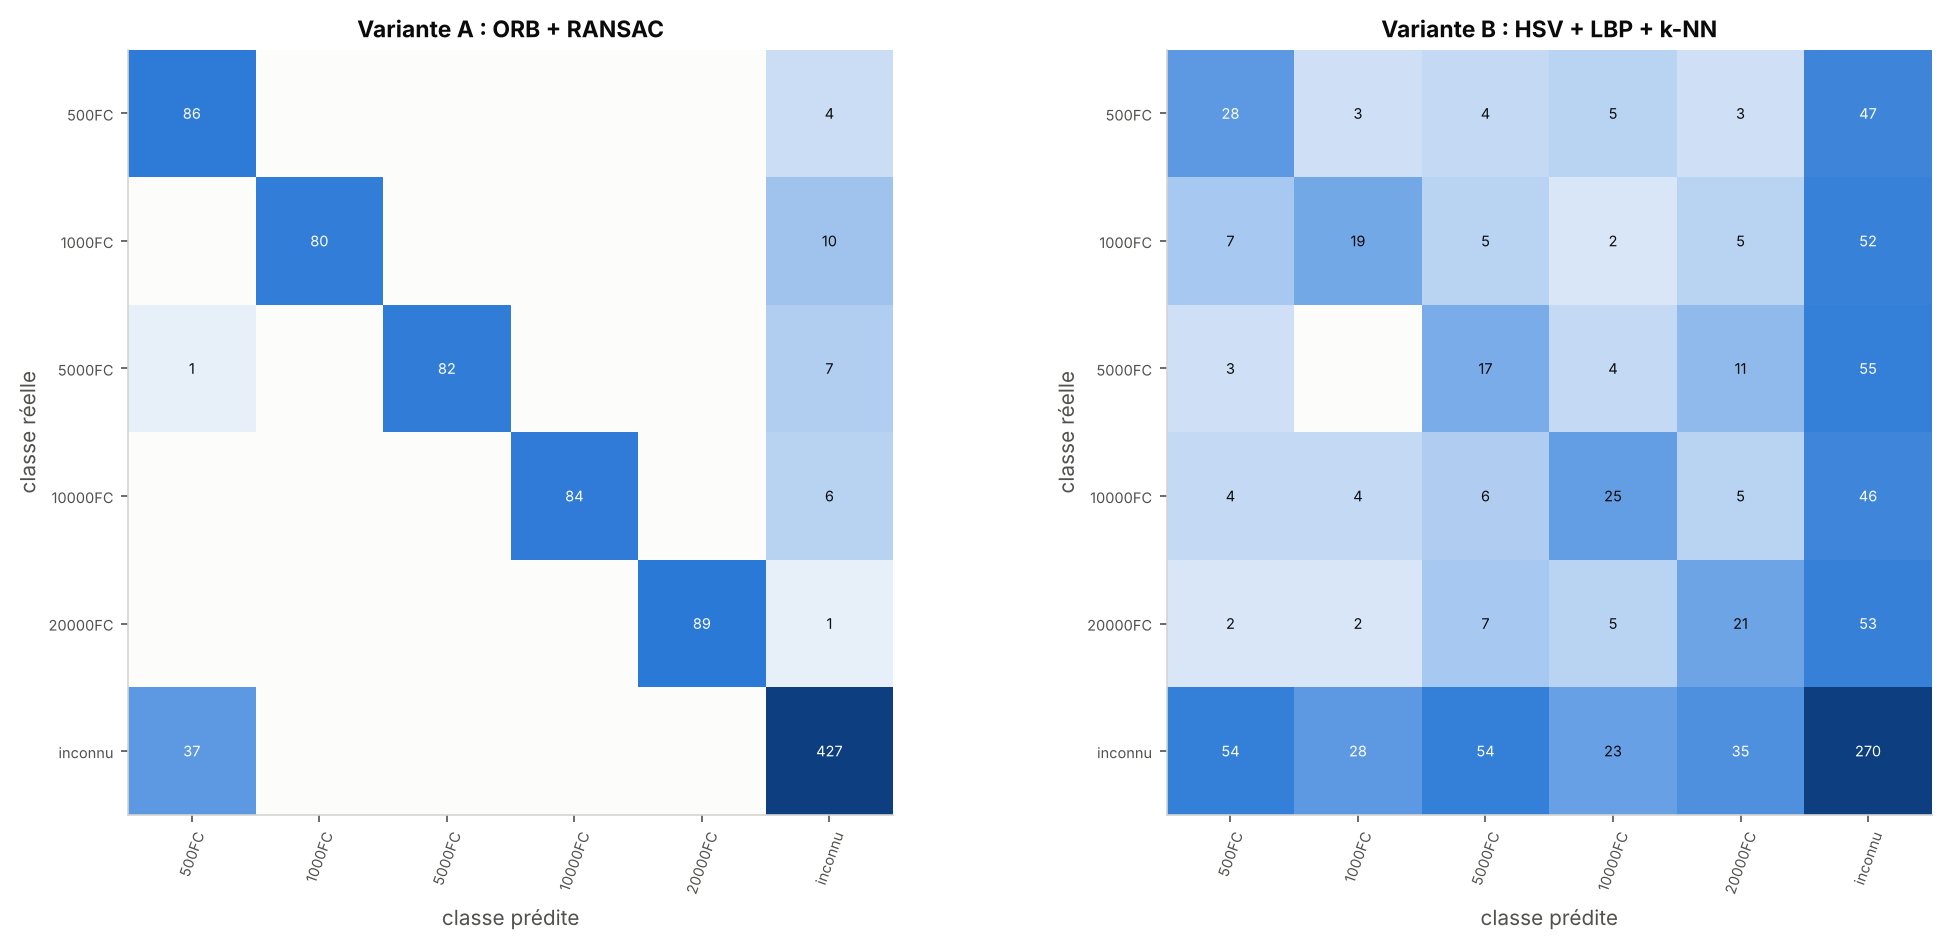

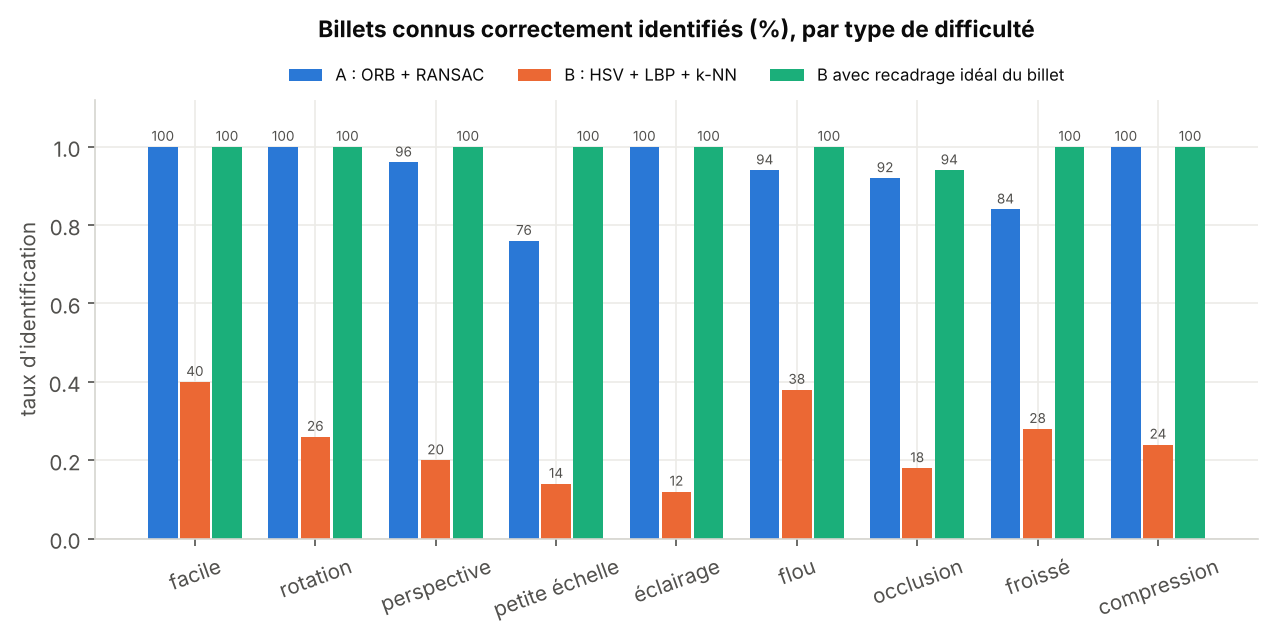

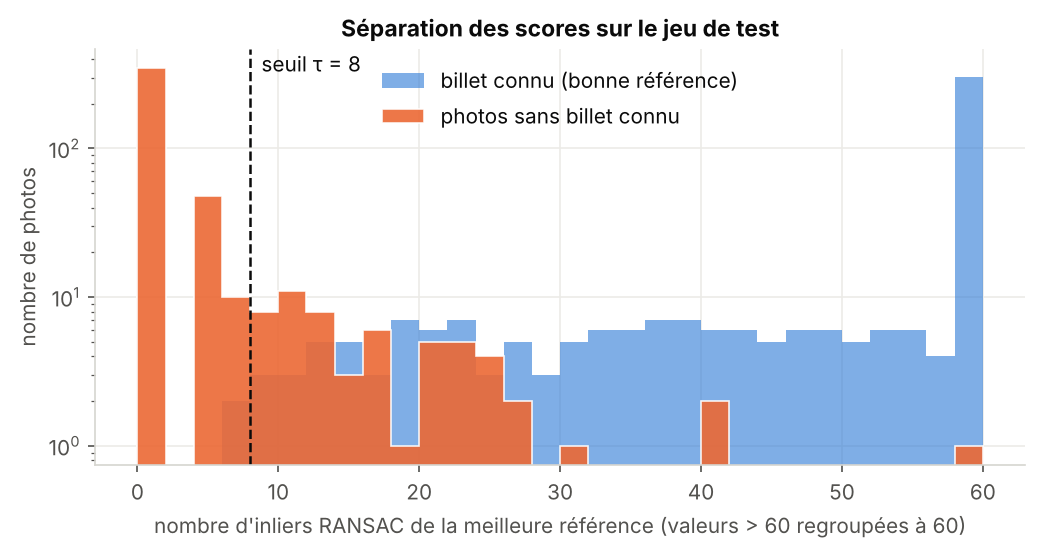

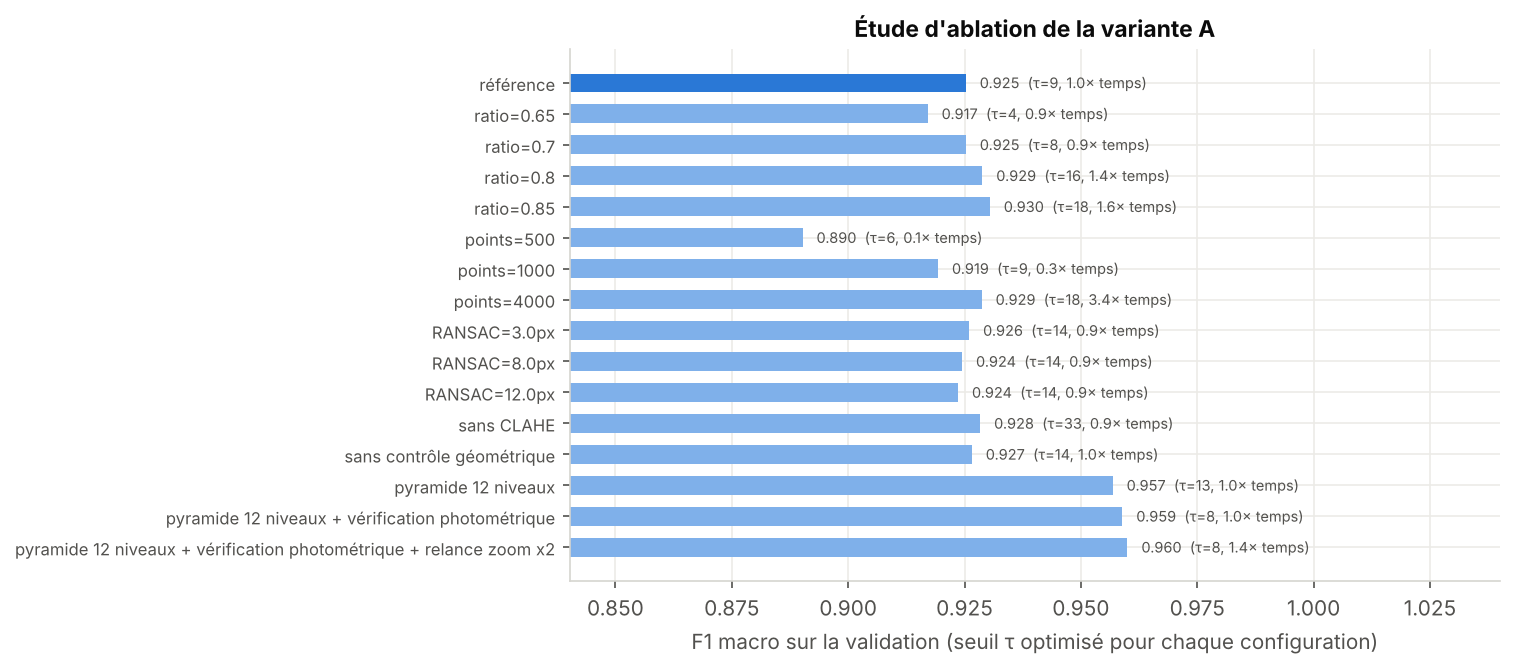

In [10]:
from IPython.display import Image, display
for f in ['09_matrices_confusion.png', '10_robustesse_categories.png', '07_distribution_scores.png', '11_ablation_a.png']:
    display(Image(filename=str(RACINE / 'figures' / f)))

## 7. Vérification rapide reproductible (sous-échantillon du test)
On ré-exécute ici la reconnaissance sur 90 photos du jeu de test (10 par catégorie) pour vérifier que l'on
retrouve les mêmes ordres de grandeur que le protocole complet.

In [11]:
import csv
dossier = RACINE / 'donnees' / 'synthetique' / 'test'
if (dossier / 'manifeste.csv').exists():
    lignes = list(csv.DictReader(open(dossier / 'manifeste.csv', encoding='utf-8')))
    reco_final = reco
    ok, n = 0, 0
    for l in lignes:
        if not (dossier / l['fichier']).exists():
            continue
        r = reco_final.predire(charger_image(dossier / l['fichier']))
        ok += r['classe'] == l['classe']; n += 1
    print(f'{ok}/{n} photos correctement traitées ({ok/max(n,1):.1%})')
else:
    print("Jeu de test absent : lancer `python construire_jeux.py` (environ 5 minutes)")

848/914 photos correctement traitées (92.8%)


## 8. Variante B en bref (pour la comparaison)
Descripteur global : histogramme HSV (teinte × saturation, valeur) + histogrammes LBP uniformes, comparés
par distance de Hellinger, décision par k-NN. Elle ne localise pas le billet et dépend du fond de l'image.

In [12]:
from billets.methode_hist import descripteur_histogrammes
img_a = charger_image(chemin_reference(DONNEES, '1000FC', 'recto'))
img_b, _ = generer_photo(rng, img_a, 'echelle')
img_c, _ = generer_photo(rng, img_a, 'facile')
da, db, dc = (descripteur_histogrammes(x) for x in (img_a, img_b, img_c))
print('distance référence <-> même billet, grand dans la photo :', round(float(np.linalg.norm(da - dc)), 3))
print('distance référence <-> même billet, petit dans la photo :', round(float(np.linalg.norm(da - db)), 3))
print('(la variante B voit surtout le fond quand le billet est petit ; ORB ne compare que les points appariés)')

distance référence <-> même billet, grand dans la photo : 1.245
distance référence <-> même billet, petit dans la photo : 1.84
(la variante B voit surtout le fond quand le billet est petit ; ORB ne compare que les points appariés)


## 9. Essayer sur sa propre photo
Sur Colab, téléverser une photo de billet puis exécuter la cellule suivante. Les références sont celles de
`donnees/billets_cdf/references/` ; si le groupe a préparé ses propres références à partir de ses photos
(`code/preparer_photos_reelles.py`), elles sont prises dans `donnees/references/`.

In [13]:
dossier_refs = RACINE / 'donnees' / 'references'
photos = sorted(glob.glob('/content/*.jpg')) if Path('/content').exists() else []
if photos:
    r2 = ReconnaisseurORB(tau=syn['A']['tau'], relance_zoom=True)
    for p in sorted(dossier_refs.glob('*.jpg')) if any(dossier_refs.glob('*.jpg')) else sorted((DONNEES / 'billets_cdf' / 'references').glob('*.jpg')):
        classe, _, face = p.stem.rpartition('_') if p.stem.endswith(('_recto','_verso')) else (p.stem, '', '')
        r2.ajouter_reference(classe, charger_image(p), face)
    for p in photos:
        img = charger_image(p); r = r2.predire(img)
        plt.figure(figsize=(8,5)); plt.imshow(rgb(annoter(img, r))); plt.axis('off'); plt.show()
else:
    print('Aucune photo téléversée dans /content.')

Aucune photo téléversée dans /content.
